# Real Bridge Column-Only Evaluation — v3 (Column ROI Cropped Inference)

Same evaluation as `eval_real_bridge_v2.ipynb`, but the models only see the **column region** instead of the whole photograph.

### What changed from v2
1. **Tight column crop**: For every image, the image, column mask, and ground-truth mask are cropped to the bounding box of the Labelbox `column` polygon (no margin), so background, sky, beams, and abutments are never sent to the GPU.
2. **Irregular column boundary**: The model input is always the rectangular bounding box. `OUTSIDE_FILL` controls the pixels inside the box but outside the column polygon:
   - `"none"` (default): keep the original image pixels, so the column edge looks the same as in the photograph.
   - `"mean"`: ImageNet mean RGB `(124, 116, 104)`, which is exactly 0 after normalization (the same value `predict_with_patches` uses to pad edge patches).
   - `"black"`: RGB 0.
3. **Cropped inference & metrics**: `predict_with_patches` (448x448, stride 224, AMP) and YOLO run on the rectangular crop; area, centerline, clDice, and orientation metrics are computed on the crop (prediction and ground truth are both zero outside the column).
4. **Metrics**: Raw-skeleton and opened-skeleton centerline metrics. The closing (D5:E1) variant from v2 is removed.
5. **Timing**: Per-model inference time on the crop is recorded in the results CSV, and the "Inference Time" section benchmarks full-frame vs. column-crop inference side by side.
6. **Consistency check**: the "Consistency Check" section compares v3 mean metrics against the v2 CSV. Differences are expected: the sliding-window grid is anchored at the crop origin, the models no longer see content outside the column bounding box, and YOLO (which resizes its input to 640 px) sees the column at a higher effective resolution.

In [1]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import csv
import json
import time
from pathlib import Path

import numpy as np
import torch
from PIL import Image, ImageDraw
from tqdm.auto import tqdm

from crack_seg import config
from crack_seg.predict import predict_with_patches
from crack_seg.utils.helpers import (
    load_model,
    predict_mask,
    predict_yolo_mask,
    warmup_gpu,
)
from crack_seg.utils.visualization import plot_overlay_comparison
from crack_seg.utils.metrics import (
    centerline_buffer_metrics,
    cldice_score,
    crack_orientation_mae,
    dice_coefficient,
    iou_score,
    pixel_accuracy,
    precision_score,
    recall_score,
    specificity_score,
)

BRIDGE_DIR = config.DATA_ROOT / "reno_bridge_sample"
ANNOTATION_FILE = BRIDGE_DIR / "Export  project - Bridge_cracks - 10_26_2026.ndjson"
RESULTS_CSV = config.BASE_DIR / "experimenting" / "real_bridge_eval_v3_metrics.csv"
V2_RESULTS_CSV = config.BASE_DIR / "experimenting" / "real_bridge_eval_v2_metrics.csv"

SKELETON_METHOD = getattr(config, "SKELETON_METHOD", "lee")
TOLERANCE_PX = float(getattr(config, "CENTERLINE_TOLERANCE_PX", 20.0))
TOL_TAG = int(TOLERANCE_PX) if TOLERANCE_PX.is_integer() else f"{TOLERANCE_PX:.1f}"
OPEN_KERNEL_SIZE = 10

# Batched sliding-window patch inference configuration
PATCH_SIZE = 448
STRIDE = 224
PATCH_BATCH_SIZE = 16
USE_AMP = True
YOLO_CONFIDENCE = 0.15

# Fill for pixels inside the column bounding box but outside the column polygon.
# "none": keep the original pixels. "mean": ImageNet mean RGB -> 0 after normalization
# (same as predict_with_patches' edge padding). "black": RGB 0.
OUTSIDE_FILL = "none"
OUTSIDE_FILL_RGB = {"mean": (124, 116, 104), "black": (0, 0, 0)}
if OUTSIDE_FILL not in ("none", *OUTSIDE_FILL_RGB):
    raise ValueError(f"Unknown OUTSIDE_FILL: {OUTSIDE_FILL!r}")

if not BRIDGE_DIR.is_dir():
    raise FileNotFoundError(f"Bridge data directory not found: {BRIDGE_DIR}")
if not ANNOTATION_FILE.is_file():
    raise FileNotFoundError(f"Labelbox export not found: {ANNOTATION_FILE}")


def cuda_sync():
    if torch.cuda.is_available():
        torch.cuda.synchronize()


print(f"Device: {config.DEVICE}")
print(f"Patch size / stride: {PATCH_SIZE} / {STRIDE}")
print(f"Patch batch size: {PATCH_BATCH_SIZE}, AMP: {USE_AMP}")
print(f"Outside-column fill: {OUTSIDE_FILL}")
print(f"Centerline tolerance: {TOLERANCE_PX}px")
print(f"Annotation file: {ANNOTATION_FILE.name}")

c:\Users\abinashm\AppData\Local\anaconda3\envs\computerVision\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda
Patch size / stride: 448 / 224
Patch batch size: 16, AMP: True
Outside-column fill: none
Centerline tolerance: 20.0px
Annotation file: Export  project - Bridge_cracks - 10_26_2026.ndjson


In [2]:
# Match each Labelbox external_id to the local image, rasterize crack and column polygons,
# then crop image / column mask / GT mask to the column bounding box and fill outside the polygon.
records = [
    json.loads(line)
    for line in ANNOTATION_FILE.read_text(encoding="utf-8").splitlines()
    if line.strip()
]
local_images = {
    path.name.casefold(): path
    for path in BRIDGE_DIR.iterdir()
    if path.is_file() and path.suffix.casefold() in (".jpg", ".jpeg", ".png")
}
record_names = [record["data_row"]["external_id"] for record in records]
record_keys = [name.casefold() for name in record_names]

if len(record_keys) != len(set(record_keys)):
    raise ValueError("The Labelbox export contains duplicate image external_id values.")
missing_images = sorted(set(record_keys) - set(local_images))
unannotated_images = sorted(set(local_images) - set(record_keys))
if missing_images or unannotated_images:
    raise ValueError(
        "Local JPGs and Labelbox rows do not match. "
        f"Missing local files: {missing_images}; without labels: {unannotated_images}"
    )

bridge_samples = []
for record in records:
    image_name = record["data_row"]["external_id"]
    image_path = local_images[image_name.casefold()]
    image = Image.open(image_path).convert("RGB")
    width, height = image.size
    attributes = record.get("media_attributes", {})
    expected_size = (attributes.get("width"), attributes.get("height"))
    if expected_size != image.size:
        raise ValueError(
            f"Image size mismatch for {image_name}: local {image.size}, Labelbox {expected_size}"
        )

    # Separate cracks and column annotations
    crack_objects = []
    column_objects = []
    for project in (record.get("projects") or {}).values():
        for label in project.get("labels", []):
            for obj in label.get("annotations", {}).get("objects", []):
                val = str(obj.get("value", "")).casefold()
                name = str(obj.get("name", "")).casefold()
                if "crack" in val or "crack" in name:
                    crack_objects.append(obj)
                elif "column" in val or "column" in name:
                    column_objects.append(obj)

    if not column_objects:
        raise ValueError(f"No column annotation found for {image_name}.")
    if not crack_objects:
        raise ValueError(f"No crack annotations found for {image_name}.")

    # 1. Rasterize full-resolution crack mask
    crack_mask = Image.new("L", image.size, 0)
    crack_draw = ImageDraw.Draw(crack_mask)
    for obj in crack_objects:
        polygon = obj.get("polygon") or []
        if len(polygon) < 3:
            raise ValueError(f"Invalid crack polygon in {image_name}.")
        points = [(round(float(p["x"])), round(float(p["y"]))) for p in polygon]
        crack_draw.polygon(points, fill=255)

    # 2. Rasterize full-resolution column mask
    col_mask = Image.new("L", image.size, 0)
    col_draw = ImageDraw.Draw(col_mask)
    for obj in column_objects:
        polygon = obj.get("polygon") or []
        if len(polygon) < 3:
            raise ValueError(f"Invalid column polygon in {image_name}.")
        points = [(round(float(p["x"])), round(float(p["y"]))) for p in polygon]
        col_draw.polygon(points, fill=255)

    # 3. Intersect cracks with column (ignore any crack outside column)
    crack_arr = np.array(crack_mask) > 128
    col_arr = np.array(col_mask) > 128
    gt_column_crack_arr = (crack_arr & col_arr).astype(np.uint8) * 255

    gt_pixels = int((gt_column_crack_arr > 128).sum())
    if gt_pixels == 0:
        raise ValueError(f"Column crack mask is empty for {image_name}.")

    # 4. Crop everything to the tight column bounding box, then fill pixels outside the polygon
    ys, xs = np.nonzero(col_arr)
    y0, y1 = int(ys.min()), int(ys.max()) + 1
    x0, x1 = int(xs.min()), int(xs.max()) + 1
    col_roi = col_arr[y0:y1, x0:x1]
    gt_roi = gt_column_crack_arr[y0:y1, x0:x1]
    roi_arr = np.array(image.crop((x0, y0, x1, y1)))
    if OUTSIDE_FILL != "none":
        roi_arr[~col_roi] = OUTSIDE_FILL_RGB[OUTSIDE_FILL]
    roi_image = Image.fromarray(roi_arr)
    assert int((gt_roi > 128).sum()) == gt_pixels, "Column crop dropped GT pixels."

    bridge_samples.append((
        image_name,
        image_path,
        roi_image,
        col_roi,
        gt_roi,
        (x0, y0, x1, y1),
    ))
    col_pct = col_arr.mean() * 100
    crop_pct = (x1 - x0) * (y1 - y0) / (width * height) * 100
    fill_pct = (~col_roi).mean() * 100
    print(
        f"{image_name} ({width}x{height}): {len(crack_objects)} crack polygons, "
        f"column {col_pct:.1f}% area -> crop {x1 - x0}x{y1 - y0} ({crop_pct:.1f}% of pixels, "
        f"{fill_pct:.1f}% of crop filled), "
        f"GT column crack pixels={gt_pixels}"
    )

print(f"\nLoaded {len(bridge_samples)} annotated bridge images (column ROI cropped).")

IMG_0731.jpeg (3213x5712): 6 crack polygons, column 67.9% area -> crop 2518x5712 (78.4% of pixels, 13.4% of crop filled), GT column crack pixels=10450
IMG_0732.jpeg (3213x5712): 28 crack polygons, column 79.9% area -> crop 2638x5712 (82.1% of pixels, 2.7% of crop filled), GT column crack pixels=17646
IMG_0733.jpeg (3213x5712): 3 crack polygons, column 60.3% area -> crop 2377x5311 (68.8% of pixels, 12.4% of crop filled), GT column crack pixels=9486
IMG_0734.jpeg (3213x5712): 22 crack polygons, column 70.4% area -> crop 2792x5712 (86.9% of pixels, 18.9% of crop filled), GT column crack pixels=31379
IMG_0735.jpeg (3213x5712): 7 crack polygons, column 81.5% area -> crop 2946x5712 (91.7% of pixels, 11.1% of crop filled), GT column crack pixels=11844
IMG_0736.jpeg (3213x5712): 13 crack polygons, column 58.4% area -> crop 2527x4734 (65.2% of pixels, 10.3% of crop filled), GT column crack pixels=9973
IMG_0737.jpeg (3213x5712): 15 crack polygons, column 60.0% area -> crop 2491x5288 (71.8% of pi

In [3]:
# Keep the same checkpoint set as eval_real_bridge_v2.ipynb; unavailable checkpoints are skipped.
MODELS_TO_EVALUATE = {
    "UNet (NCCD-PF)": {
        "type": "unet",
        "path": config.CHECKPOINT_DIR / "unet_NCCD-PF_Dataset.pth",
    },
    "UNet (4 Datasets)": {
        "type": "unet",
        "path": config.CHECKPOINT_DIR / "unet_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500.pth",
    },
    "SegFormer (4 Datasets)": {
        "type": "segformer",
        "path": config.CHECKPOINT_DIR / "segformer_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500.pth",
    },
    "SegFormer (Focal)": {
        "type": "segformer",
        "path": config.CHECKPOINT_DIR / "segformer_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500_focal.pth",
    },
    "SegFormer (Dice+Focal)": {
        "type": "segformer",
        "path": config.CHECKPOINT_DIR / "segformer_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500_dice_focal.pth",
    },
    "YOLO-seg (4 Datasets)": {
        "type": "yolo",
        "path": config.CHECKPOINT_DIR
        / "yolo_runs"
        / "yolo_seg_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500.pt",
    },
}

active_models = {
    name: info
    for name, info in MODELS_TO_EVALUATE.items()
    if Path(info["path"]).is_file()
}
for name, info in MODELS_TO_EVALUATE.items():
    status = "found" if name in active_models else "missing; skipped"
    print(f"{status:16} {name}: {info['path']}")
if not active_models:
    raise FileNotFoundError(f"No evaluation checkpoints found in {config.CHECKPOINT_DIR}.")

loaded_models = {}
for name, info in active_models.items():
    loaded_models[name] = (
        info["type"],
        load_model(info["type"], info["path"], device=config.DEVICE),
    )
print(f"\nLoaded {len(loaded_models)} model(s).")

# Warm up CUDA kernels (and YOLO's predictor) so the first timed call is not inflated.
warmup_gpu(
    [model for model_type, model in loaded_models.values() if model_type != "yolo"],
    patch_batch_size=PATCH_BATCH_SIZE,
    patch_size=PATCH_SIZE,
    device=config.DEVICE,
    use_amp=USE_AMP,
)
for model_type, model in loaded_models.values():
    if model_type == "yolo":
        predict_yolo_mask(bridge_samples[0][2], model, conf=YOLO_CONFIDENCE)

found            UNet (NCCD-PF): C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\checkpoints\unet_NCCD-PF_Dataset.pth
found            UNet (4 Datasets): C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\checkpoints\unet_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500.pth
found            SegFormer (4 Datasets): C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\checkpoints\segformer_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500.pth
found            SegFormer (Focal): C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\checkpoints\segformer_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500_focal.pth
found            SegFormer (Dice+Focal): C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentati

In [4]:
metric_names = [
    "IoU",
    "Dice",
    "Accuracy",
    "Precision",
    "Recall",
    "Specificity",
    "clDice",
    f"Centerline_Prec@{TOL_TAG}",
    f"Centerline_Rec@{TOL_TAG}",
    f"Centerline_F1@{TOL_TAG}",
    f"Centerline_IoU@{TOL_TAG}",
    "Orientation_MAE(deg)",
    "clDice (Opened)",
    f"Centerline_Prec@{TOL_TAG} (Opened)",
    f"Centerline_Rec@{TOL_TAG} (Opened)",
    f"Centerline_F1@{TOL_TAG} (Opened)",
    f"Centerline_IoU@{TOL_TAG} (Opened)",
]
timing_names = ["Inference_ROI(s)"]

topology_variants = [
    ("", {}),
    (
        " (Opened)",
        {"morph_op": "open", "morph_kernel_size": OPEN_KERNEL_SIZE},
    ),
]

image_results = []
with torch.inference_mode():
    for image_name, _, roi_image, col_roi, gt_roi, _ in tqdm(
        bridge_samples, desc="Evaluating bridge images (column ROI crop, patched inference)"
    ):
        col_mask_2d = col_roi.astype(np.uint8)
        col_target_tensor = torch.from_numpy(col_mask_2d.astype(np.float32))
        gt_bin = ((gt_roi > 128) & col_roi).astype(np.uint8)
        target_masked = torch.from_numpy(gt_bin.astype(np.float32))

        for model_name, (model_type, model) in loaded_models.items():
            cuda_sync()
            t0 = time.perf_counter()
            if model_type in ("unet", "segformer"):
                raw_prob = predict_with_patches(
                    image_path=roi_image,
                    model=model,
                    device=config.DEVICE,
                    patch_size=PATCH_SIZE,
                    stride=STRIDE,
                    batch_size=PATCH_BATCH_SIZE,
                    use_amp=USE_AMP,
                )
                probability = torch.from_numpy(raw_prob)
            elif model_type == "yolo":
                yolo_mask_bool = predict_yolo_mask(roi_image, model, conf=YOLO_CONFIDENCE)
                probability = torch.from_numpy(yolo_mask_bool.astype(np.float32))
            else:
                raise ValueError(f"Unsupported model type: {model_type}")
            cuda_sync()
            inference_s = time.perf_counter() - t0

            # Mask prediction and target strictly to the column region
            probability_masked = probability * col_target_tensor
            pred_bin = (probability_masked.numpy() >= 0.5).astype(np.uint8) * col_mask_2d

            # Area metrics on masked tensors
            iou_val = float(iou_score(probability_masked, target_masked).item())
            dice_val = float(dice_coefficient(probability_masked, target_masked).item())
            if (probability_masked >= 0.5).sum() == 0:
                prec_val = 0.0
            else:
                prec_val = float(precision_score(probability_masked, target_masked).item())
            rec_val = float(recall_score(probability_masked, target_masked).item())

            # Pixel accuracy and specificity strictly within column pixels
            col_bool = (col_target_tensor >= 0.5)
            if col_bool.any():
                prob_col_1d = probability[col_bool].view(1, 1, 1, -1)
                target_col_1d = target_masked[col_bool].view(1, 1, 1, -1)
                acc_val = float(pixel_accuracy(prob_col_1d, target_col_1d).item())
                spec_val = float(specificity_score(prob_col_1d, target_col_1d).item())
            else:
                acc_val = 0.0
                spec_val = 0.0

            row = {
                "image": image_name,
                "model": model_name,
                "IoU": iou_val,
                "Dice": dice_val,
                "Accuracy": acc_val,
                "Precision": prec_val,
                "Recall": rec_val,
                "Specificity": spec_val,
                "Orientation_MAE(deg)": float(crack_orientation_mae(pred_bin, gt_bin)),
                "Inference_ROI(s)": inference_s,
            }

            for suffix, morph_options in topology_variants:
                common_options = {
                    "method": SKELETON_METHOD,
                    "prune_spurs": False,
                    **morph_options,
                }
                cldice = cldice_score(pred_bin, gt_bin, **common_options)
                centerline = centerline_buffer_metrics(
                    pred_bin,
                    gt_bin,
                    tolerance_px=TOLERANCE_PX,
                    **common_options,
                )
                row[f"clDice{suffix}"] = float(cldice)
                row[f"Centerline_Prec@{TOL_TAG}{suffix}"] = centerline["precision"]
                row[f"Centerline_Rec@{TOL_TAG}{suffix}"] = centerline["recall"]
                row[f"Centerline_F1@{TOL_TAG}{suffix}"] = centerline["f1_score"]
                row[f"Centerline_IoU@{TOL_TAG}{suffix}"] = centerline["iou"]
            image_results.append(row)

print(f"Completed {len(bridge_samples)} image(s) across {len(loaded_models)} model(s) on column ROI crops.")

Evaluating bridge images (column ROI crop, patched inference): 100%|██████████| 9/9 [07:27<00:00, 49.75s/it]

Completed 9 image(s) across 6 model(s) on column ROI crops.


In [5]:
# Macro-average per-image scores on column ROI.
summary_rows = []
for model_name in loaded_models:
    model_rows = [row for row in image_results if row["model"] == model_name]
    summary = {
        "image": "MEAN",
        "model": model_name,
        **{
            metric: float(np.mean([row[metric] for row in model_rows]))
            for metric in [*metric_names, *timing_names]
        },
    }
    summary_rows.append(summary)

from html import escape
from IPython.display import HTML, display

mean_metrics = {row["model"]: row for row in summary_rows}
model_names = list(loaded_models)
area_metrics = ["IoU", "Dice", "Accuracy", "Precision", "Recall", "Specificity"]
topology_raw_metrics = [
    "clDice",
    f"Centerline_Prec@{TOL_TAG}",
    f"Centerline_Rec@{TOL_TAG}",
    f"Centerline_F1@{TOL_TAG}",
    f"Centerline_IoU@{TOL_TAG}",
    "Orientation_MAE(deg)",
]
topology_opened_metrics = [
    "clDice (Opened)",
    f"Centerline_Prec@{TOL_TAG} (Opened)",
    f"Centerline_Rec@{TOL_TAG} (Opened)",
    f"Centerline_F1@{TOL_TAG} (Opened)",
    f"Centerline_IoU@{TOL_TAG} (Opened)",
]

html = [
    "<div style='margin: 15px 0; overflow-x: auto;'>",
    "<table style='border-collapse: collapse; font-family: -apple-system, BlinkMacSystemFont, Arial, sans-serif; width: 100%; border: 1px solid #d0d7de;'>",
    "<thead><tr style='background-color: #24292f; color: white;'>",
    "<th style='padding: 10px 14px; text-align: left; font-size: 14px;'>Metric (Column Only)</th>",
]
for model_name in model_names:
    html.append(
        f"<th style='padding: 10px 14px; text-align: right; font-size: 14px;'>{escape(model_name)}</th>"
    )
html.append("</tr></thead><tbody>")

def add_html_section(title, metrics, background_color):
    html.append(
        f"<tr style='background-color: {background_color}; font-weight: 600; color: #24292f;'>"
        f"<td colspan='{1 + len(model_names)}' style='padding: 9px 14px; font-size: 13px;'>{escape(title)}</td></tr>"
    )
    for metric in metrics:
        html.append("<tr style='border-bottom: 1px solid #e1e4e8;'>")
        html.append(
            f"<td style='padding: 8px 14px; text-align: left; font-size: 13px;'>{escape(metric)}</td>"
        )
        for model_name in model_names:
            value = mean_metrics[model_name][metric]
            html.append(
                f"<td style='padding: 8px 14px; text-align: right; font-family: SFMono-Regular, Consolas, monospace; font-size: 13px;'>{value:.4f}</td>"
            )
        html.append("</tr>")

add_html_section("1. Area-based Metrics (Column Domain)", area_metrics, "#ddf4ff")
add_html_section("2. Topology & Centerline Metrics (Raw Skeleton)", topology_raw_metrics, "#fff8c5")
add_html_section(
    f"3. Topology & Centerline Metrics (Branch Removed: {OPEN_KERNEL_SIZE}px Open)",
    topology_opened_metrics,
    "#dafbe1",
)
add_html_section("4. Mean Inference Time per Image on Column Crop (s)", timing_names, "#f6f8fa")
html.append("</tbody></table></div>")
display(HTML("".join(html)))

RESULTS_CSV.parent.mkdir(parents=True, exist_ok=True)
fieldnames = ["image", "model", *metric_names, *timing_names]
with RESULTS_CSV.open("w", newline="", encoding="utf-8") as csv_file:
    writer = csv.DictWriter(csv_file, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(image_results)
    writer.writerows(summary_rows)
print(f"Macro-average across {len(bridge_samples)} annotated images (column ROI crops); lower Orientation_MAE is better.")
print(f"Per-image and mean metrics saved to: {RESULTS_CSV}")

Macro-average across 9 annotated images (column ROI crops); lower Orientation_MAE is better.
Per-image and mean metrics saved to: C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\experimenting\real_bridge_eval_v3_metrics.csv


## Inference Time: Full Frame vs. Column ROI Crop

Runs every loaded model on each image twice — once on the full photograph (as in v2) and once on the column crop — with identical patch settings, AMP, and CUDA synchronization around each call (`predict_mask`). Both inputs are pre-loaded PIL images, so JPEG decoding is excluded from the timings. This cell re-runs inference, so skip it if you only need metrics.

In [6]:
def count_patches(width, height):
    return len(range(0, height, STRIDE)) * len(range(0, width, STRIDE))


timing_rows = []
for image_name, image_path, roi_image, *_ in tqdm(bridge_samples, desc="Timing full frame vs column crop"):
    full_image = Image.open(image_path).convert("RGB")
    for model_name, (model_type, model) in loaded_models.items():
        timings = {}
        for label, source in (("full", full_image), ("roi", roi_image)):
            _, timings[label] = predict_mask(
                model,
                source,
                device=config.DEVICE,
                model_type=model_type,
                use_patches=True,
                patch_size=PATCH_SIZE,
                stride=STRIDE,
                batch_size=PATCH_BATCH_SIZE,
                use_amp=USE_AMP,
                yolo_conf=YOLO_CONFIDENCE,
            )
        timing_rows.append({
            "image": image_name,
            "model": model_name,
            "full_patches": count_patches(*full_image.size),
            "roi_patches": count_patches(*roi_image.size),
            "full_s": timings["full"],
            "roi_s": timings["roi"],
        })

total_full_patches = sum(count_patches(*Image.open(s[1]).size) for s in bridge_samples)
total_roi_patches = sum(count_patches(*s[2].size) for s in bridge_samples)
print(
    f"Patches per model over {len(bridge_samples)} images: full={total_full_patches}, "
    f"column crop={total_roi_patches} ({1 - total_roi_patches / total_full_patches:.1%} fewer)\n"
)
print(f"{'Model':<26}{'Full frame (s)':>16}{'Column crop (s)':>17}{'Speedup':>10}")
print("-" * 69)
for model_name in loaded_models:
    rows = [row for row in timing_rows if row["model"] == model_name]
    full_total = sum(row["full_s"] for row in rows)
    roi_total = sum(row["roi_s"] for row in rows)
    print(f"{model_name:<26}{full_total:>16.2f}{roi_total:>17.2f}{full_total / roi_total:>9.2f}x")
full_all = sum(row["full_s"] for row in timing_rows)
roi_all = sum(row["roi_s"] for row in timing_rows)
print("-" * 69)
print(f"{'All models':<26}{full_all:>16.2f}{roi_all:>17.2f}{full_all / roi_all:>9.2f}x")

Timing full frame vs column crop: 100%|██████████| 9/9 [03:16<00:00, 21.83s/it]

Patches per model over 9 images: full=3510, column crop=2792 (20.5% fewer)

Model                       Full frame (s)  Column crop (s)   Speedup
---------------------------------------------------------------------
UNet (NCCD-PF)                       23.13            19.61     1.18x
UNet (4 Datasets)                    23.11            18.25     1.27x
SegFormer (4 Datasets)               20.61            15.91     1.29x
SegFormer (Focal)                    20.08            15.93     1.26x
SegFormer (Dice+Focal)               19.97            15.89     1.26x
YOLO-seg (4 Datasets)                 1.95             1.04     1.87x
---------------------------------------------------------------------
All models                          108.84            86.64     1.26x


## Consistency Check Against v2 (Full-Frame Inference)

Difference of v3 mean metrics minus v2 mean metrics (`real_bridge_eval_v2_metrics.csv`). Differences come from three sources: the sliding-window grid is anchored at the crop origin instead of the image origin, the models no longer see content outside the column bounding box, and YOLO resizes its input to 640 px, so it sees the column at a higher effective resolution on the crop.

In [7]:
if not V2_RESULTS_CSV.is_file():
    print(f"v2 results not found ({V2_RESULTS_CSV}); run eval_real_bridge_v2.ipynb first to compare.")
else:
    with V2_RESULTS_CSV.open(newline="", encoding="utf-8") as csv_file:
        v2_means = {row["model"]: row for row in csv.DictReader(csv_file) if row["image"] == "MEAN"}
    short_names = [name.replace(" Datasets", "D").replace("SegFormer", "SegF") for name in model_names]
    print(f"{'v3 - v2 (mean)':<38}" + "".join(f"{name:>18}" for name in short_names))
    print("-" * (38 + 18 * len(model_names)))
    for metric in metric_names:
        cells = []
        for model_name in model_names:
            if model_name in v2_means and v2_means[model_name].get(metric):
                diff = mean_metrics[model_name][metric] - float(v2_means[model_name][metric])
                cells.append(f"{diff:>+18.4f}")
            else:
                cells.append(f"{'n/a':>18}")
        print(f"{metric:<38}" + "".join(cells))

v3 - v2 (mean)                            UNet (NCCD-PF)         UNet (4D)         SegF (4D)      SegF (Focal) SegF (Dice+Focal)     YOLO-seg (4D)
--------------------------------------------------------------------------------------------------------------------------------------------------
IoU                                              -0.2852           -0.3260           -0.3126           +0.0000           -0.3245           -0.0945
Dice                                             -0.4029           -0.4172           -0.4038           +0.0000           -0.4096           -0.1447
Accuracy                                         +0.0057           +0.0066           +0.0036           +0.0122           +0.0036           +0.0129
Precision                                        -0.5320           -0.5870           -0.5268           +0.0000           -0.6102           -0.1387
Recall                                           -0.0966           -0.2323           -0.0007           +0.0000        

## Visualizations & Model Overlay Comparisons (Full Image)

Inference runs on the column ROI crop (as in the evaluation above), then each prediction is pasted back into the full-resolution frame, so all panels are shown on the original image:
1. **Original Bridge Image**
2. **Ground Truth Mask** (Column Cracks, with cyan Column ROI outline)
3. **UNet Overlay** (Column Cracks Only, with crop inference runtime)
4. **SegFormer (Dice+Focal) Overlay** (Column Cracks Only, with crop inference runtime)
5. **YOLO-seg Overlay** (Column Cracks Only, with crop inference runtime)

Generating 5-panel full-image overlay visualizations for 9 bridge image(s)...



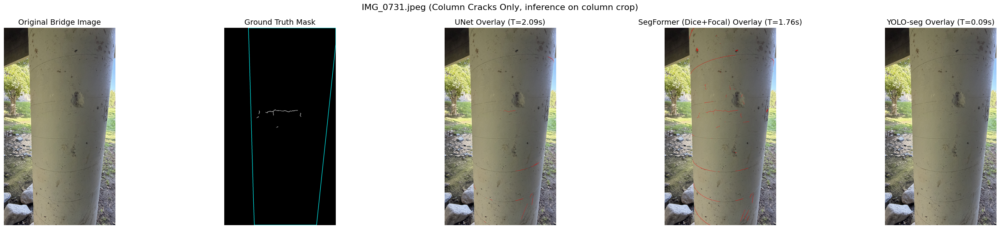

  IMG_0731.jpeg                                                | UNet: 2.09s | SegFormer (Dice+Focal): 1.76s | YOLO: 0.09s
    Saved figure to: C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\experimenting\output\overlay_column_v3_IMG_0731.png


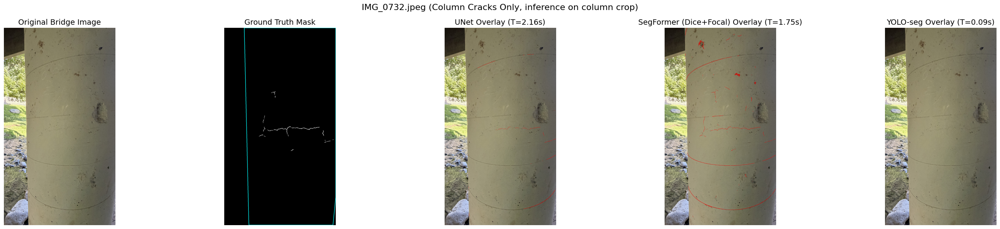

  IMG_0732.jpeg                                                | UNet: 2.16s | SegFormer (Dice+Focal): 1.75s | YOLO: 0.09s
    Saved figure to: C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\experimenting\output\overlay_column_v3_IMG_0732.png


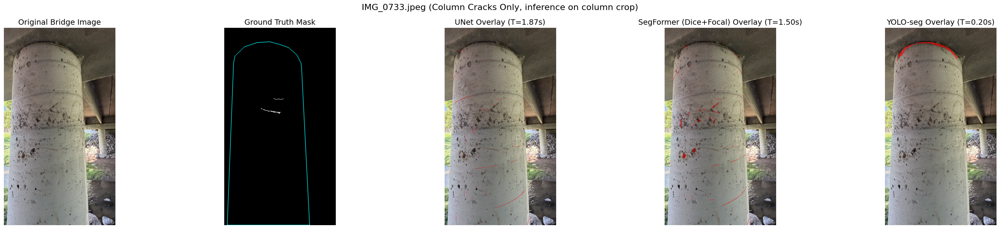

  IMG_0733.jpeg                                                | UNet: 1.87s | SegFormer (Dice+Focal): 1.50s | YOLO: 0.20s
    Saved figure to: C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\experimenting\output\overlay_column_v3_IMG_0733.png


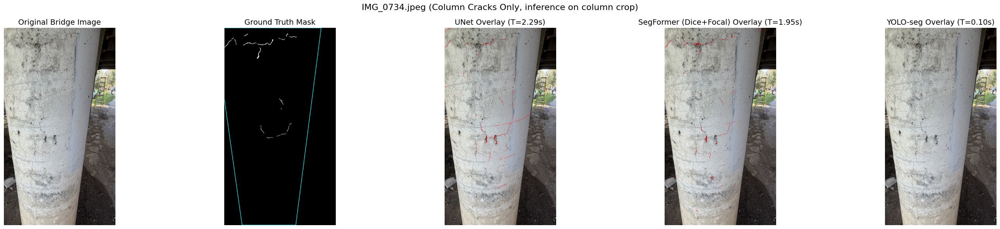

  IMG_0734.jpeg                                                | UNet: 2.29s | SegFormer (Dice+Focal): 1.95s | YOLO: 0.10s
    Saved figure to: C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\experimenting\output\overlay_column_v3_IMG_0734.png


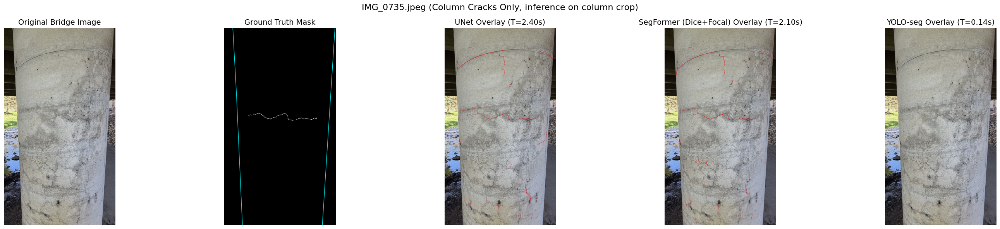

  IMG_0735.jpeg                                                | UNet: 2.40s | SegFormer (Dice+Focal): 2.10s | YOLO: 0.14s
    Saved figure to: C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\experimenting\output\overlay_column_v3_IMG_0735.png


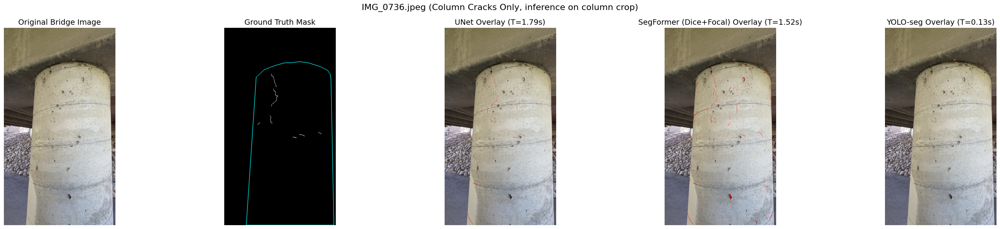

  IMG_0736.jpeg                                                | UNet: 1.79s | SegFormer (Dice+Focal): 1.52s | YOLO: 0.13s
    Saved figure to: C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\experimenting\output\overlay_column_v3_IMG_0736.png


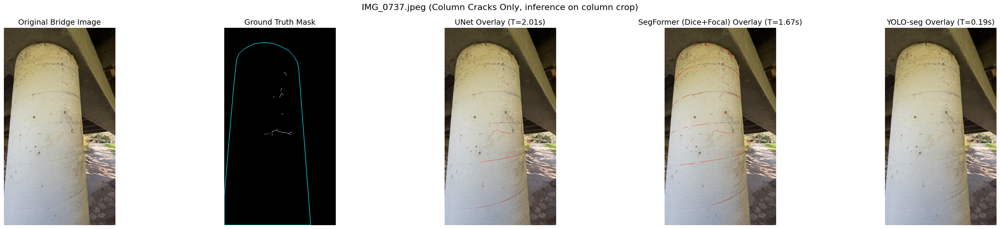

  IMG_0737.jpeg                                                | UNet: 2.01s | SegFormer (Dice+Focal): 1.67s | YOLO: 0.19s
    Saved figure to: C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\experimenting\output\overlay_column_v3_IMG_0737.png


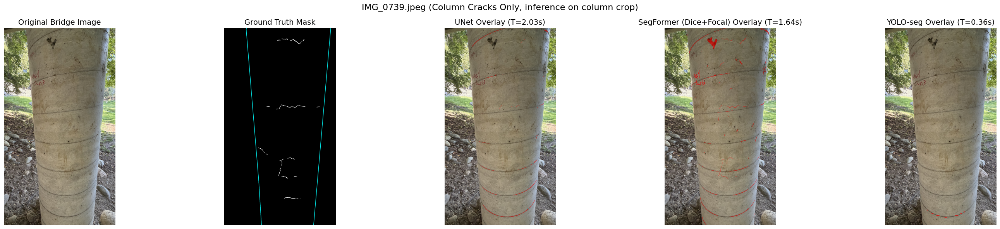

  IMG_0739.jpeg                                                | UNet: 2.03s | SegFormer (Dice+Focal): 1.64s | YOLO: 0.36s
    Saved figure to: C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\experimenting\output\overlay_column_v3_IMG_0739.png


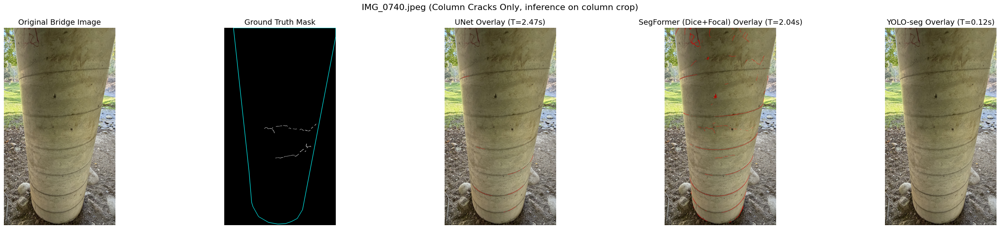

  IMG_0740.jpeg                                                | UNet: 2.47s | SegFormer (Dice+Focal): 2.04s | YOLO: 0.12s
    Saved figure to: C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\experimenting\output\overlay_column_v3_IMG_0740.png


In [8]:
# ==============================================================================
# Model Overlay Visualization on Real Bridge Samples (Full Image)
# Inference runs on the column ROI crop; masks are mapped back to full-image coordinates.
# Shows: Original Image | Ground Truth Mask | UNet Overlay | SegFormer (Dice+Focal) Overlay | YOLO-seg Overlay
# ==============================================================================
import cv2

# Plotting only: full-resolution panels are downsampled so the long side is at most this many px
# (each panel is drawn at ~900 px anyway). Axes keep full-image pixel coordinates.
DISPLAY_MAX_SIDE = 2000


def to_display(mask, size, min_coverage=0.0):
    # Area-resize; with min_coverage=0, any covered pixel is kept so thin cracks stay visible
    return cv2.resize(mask.astype(np.float32), size, interpolation=cv2.INTER_AREA) > min_coverage


def first_loaded(*names):
    for name in names:
        if name in loaded_models:
            return loaded_models[name]
    raise ValueError(f"None of {names} were found in loaded_models.")


models_to_visualize = {
    "UNet": first_loaded("UNet (4 Datasets)", "UNet (NCCD-PF)"),
    "SegFormer (Dice+Focal)": first_loaded("SegFormer (Dice+Focal)", "SegFormer (4 Datasets)"),
    "YOLO-seg": first_loaded("YOLO-seg (4 Datasets)"),
}

# Output directory for saving comparison overlay figures
OUTPUT_DIR = config.BASE_DIR / "experimenting" / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Generating 5-panel full-image overlay visualizations for {len(bridge_samples)} bridge image(s)...\n")

overlay_results = []
for image_name, image_path, roi_image, col_roi, gt_roi, (x0, y0, x1, y1) in bridge_samples:
    full_image = Image.open(image_path).convert("RGB")
    width, height = full_image.size

    # Map the column and GT masks from crop coordinates back to the full image
    col_full = np.zeros((height, width), dtype=bool)
    col_full[y0:y1, x0:x1] = col_roi
    gt_full = np.zeros((height, width), dtype=bool)
    gt_full[y0:y1, x0:x1] = gt_roi > 128

    predictions = {}
    timings = {}
    overlays = {"Ground Truth Mask": gt_full}
    for name, (model_type, model) in models_to_visualize.items():
        pred_roi, elapsed = predict_mask(
            model,
            roi_image,
            device=config.DEVICE,
            model_type=model_type,
            use_patches=True,
            patch_size=PATCH_SIZE,
            stride=STRIDE,
            batch_size=PATCH_BATCH_SIZE,
            use_amp=USE_AMP,
            yolo_conf=YOLO_CONFIDENCE,
        )
        pred_full = np.zeros((height, width), dtype=bool)
        pred_full[y0:y1, x0:x1] = pred_roi & col_roi
        predictions[name] = pred_full
        timings[name] = elapsed
        overlays[f"{name} Overlay (T={elapsed:.2f}s)"] = pred_full

    scale = min(1.0, DISPLAY_MAX_SIDE / max(width, height))
    display_size = (round(width * scale), round(height * scale))
    save_fig_path = OUTPUT_DIR / f"overlay_column_v3_{Path(image_name).stem}.png"
    fig, axes = plot_overlay_comparison(
        image=full_image.resize(display_size, Image.Resampling.LANCZOS),
        overlays={title: to_display(mask, display_size) for title, mask in overlays.items()},
        original_title="Original Bridge Image",
        suptitle=f"{image_name} (Column Cracks Only, inference on column crop)",
        alpha=0.6,
        save_path=save_fig_path,
        show=True,
        roi_mask=to_display(col_full, display_size, min_coverage=0.5),
        roi_color=(0, 255, 255),  # Cyan contour highlighting column boundary
    )
    # Map the downsampled panels back onto full-image pixel coordinates
    for ax in axes:
        for ax_image in ax.get_images():
            ax_image.set_extent((-0.5, width - 0.5, height - 0.5, -0.5))
        ax.set_xlim(-0.5, width - 0.5)
        ax.set_ylim(height - 0.5, -0.5)
    result = {
        "predictions": predictions,
        "timings": timings,
        "overlays": overlays,
        "fig": fig,
        "axes": axes,
    }
    t_unet = timings.get("UNet", 0.0)
    t_seg = timings.get("SegFormer (Dice+Focal)", 0.0)
    t_yolo = timings.get("YOLO-seg", 0.0)
    print(f"  {image_name:<60} | UNet: {t_unet:.2f}s | SegFormer (Dice+Focal): {t_seg:.2f}s | YOLO: {t_yolo:.2f}s")
    print(f"    Saved figure to: {save_fig_path}")
    overlay_results.append(result)

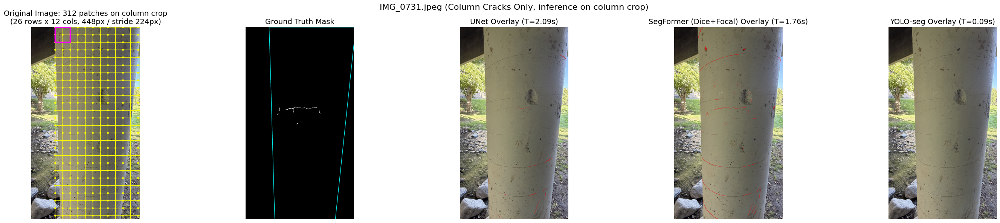

  IMG_0731.jpeg                                                | crop 2518x5712 | 312 patches (26x12), 72 zero-padded at the edges
    Saved figure to: C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\experimenting\output\overlay_column_v3_patches_IMG_0731.png


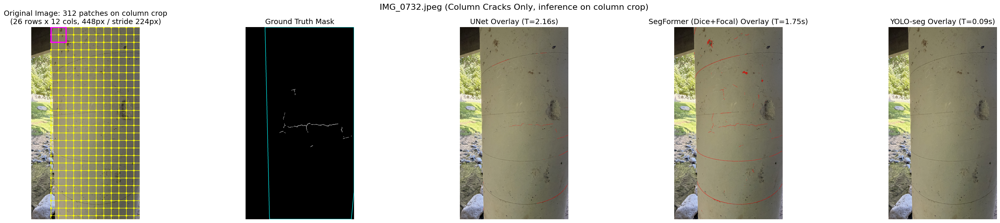

  IMG_0732.jpeg                                                | crop 2638x5712 | 312 patches (26x12), 72 zero-padded at the edges
    Saved figure to: C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\experimenting\output\overlay_column_v3_patches_IMG_0732.png


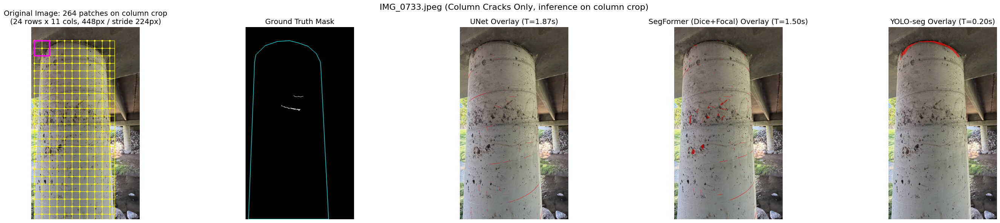

  IMG_0733.jpeg                                                | crop 2377x5311 | 264 patches (24x11), 66 zero-padded at the edges
    Saved figure to: C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\experimenting\output\overlay_column_v3_patches_IMG_0733.png


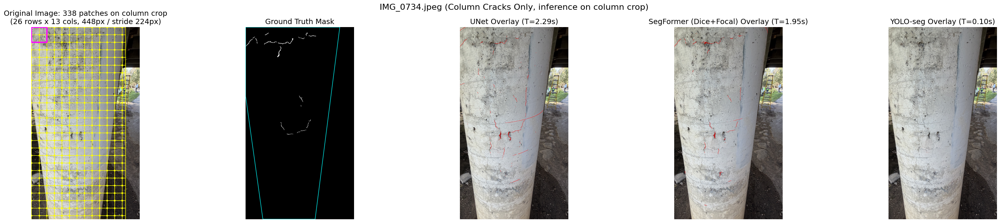

  IMG_0734.jpeg                                                | crop 2792x5712 | 338 patches (26x13), 74 zero-padded at the edges
    Saved figure to: C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\experimenting\output\overlay_column_v3_patches_IMG_0734.png


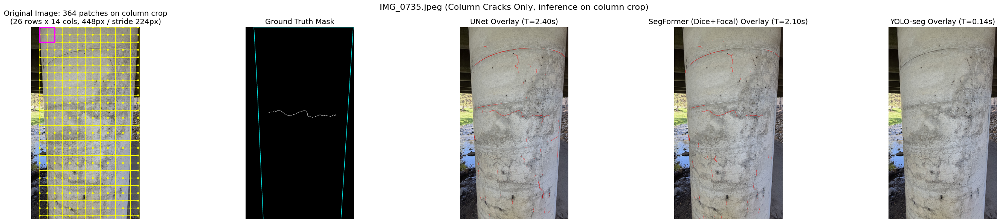

  IMG_0735.jpeg                                                | crop 2946x5712 | 364 patches (26x14), 76 zero-padded at the edges
    Saved figure to: C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\experimenting\output\overlay_column_v3_patches_IMG_0735.png


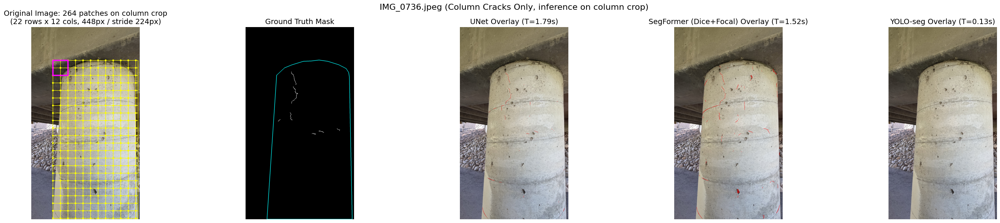

  IMG_0736.jpeg                                                | crop 2527x4734 | 264 patches (22x12), 64 zero-padded at the edges
    Saved figure to: C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\experimenting\output\overlay_column_v3_patches_IMG_0736.png


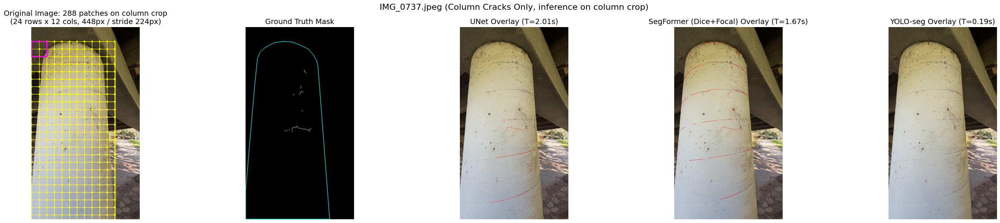

  IMG_0737.jpeg                                                | crop 2491x5288 | 288 patches (24x12), 68 zero-padded at the edges
    Saved figure to: C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\experimenting\output\overlay_column_v3_patches_IMG_0737.png


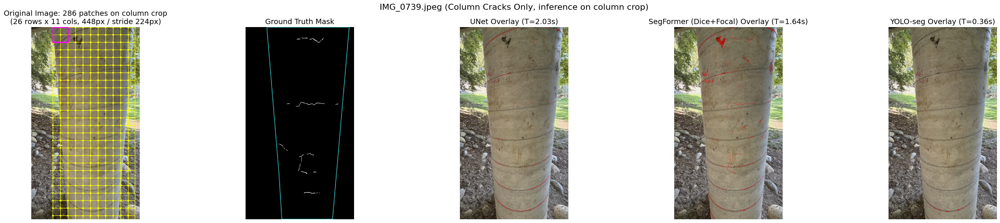

  IMG_0739.jpeg                                                | crop 2439x5712 | 286 patches (26x11), 70 zero-padded at the edges
    Saved figure to: C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\experimenting\output\overlay_column_v3_patches_IMG_0739.png


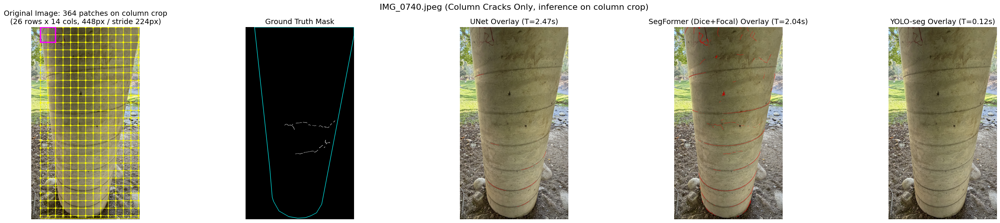

  IMG_0740.jpeg                                                | crop 2949x5683 | 364 patches (26x14), 76 zero-padded at the edges
    Saved figure to: C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\experimenting\output\overlay_column_v3_patches_IMG_0740.png


In [9]:
# ==============================================================================
# Patch Outline on the Original Image (1st panel)
# Redraws the figures from the previous cell (no re-inference) with the sliding-window
# patches that predict_with_patches sends to UNet / SegFormer: one patch every STRIDE px,
# each PATCH_SIZE px, clipped at the crop edge (and zero-padded to PATCH_SIZE before the model).
# Patches are offset by the crop origin (x0, y0) to sit on the full image.
# YOLO resizes the whole crop instead, so it does not use these patches.
# ==============================================================================
from IPython.display import display
from matplotlib.patches import Rectangle

PATCH_GID = "patch_outline"

for (image_name, _, roi_image, _, _, (x0, y0, _, _)), result in zip(bridge_samples, overlay_results):
    fig, ax = result["fig"], result["axes"][0]
    # Remove outlines from a previous run of this cell
    for artist in [*ax.patches, *ax.collections, *ax.texts]:
        if artist.get_gid() == PATCH_GID:
            artist.remove()
    xlim, ylim = ax.get_xlim(), ax.get_ylim()

    width, height = roi_image.size
    ys = range(0, height, STRIDE)
    xs = range(0, width, STRIDE)
    n_patches = len(ys) * len(xs)
    n_padded = sum(
        1 for y in ys for x in xs if y + PATCH_SIZE > height or x + PATCH_SIZE > width
    )

    # Same patch coordinates as predict_with_patches
    for y in ys:
        for x in xs:
            y_end = min(y + PATCH_SIZE, height)
            x_end = min(x + PATCH_SIZE, width)
            ax.add_patch(Rectangle(
                (x0 + x, y0 + y), x_end - x, y_end - y,
                fill=False, edgecolor="yellow", linewidth=0.8, alpha=0.8, gid=PATCH_GID,
            ))
    # Patch origins, plus the first patch highlighted to show one full PATCH_SIZE window
    origins = np.array([(x0 + x, y0 + y) for y in ys for x in xs])
    ax.scatter(origins[:, 0], origins[:, 1], s=6, c="yellow", gid=PATCH_GID)
    ax.add_patch(Rectangle(
        (x0, y0), min(PATCH_SIZE, width), min(PATCH_SIZE, height),
        fill=False, edgecolor="magenta", linewidth=2.5, gid=PATCH_GID,
    ))
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_title(
        f"Original Image: {n_patches} patches on column crop\n"
        f"({len(ys)} rows x {len(xs)} cols, {PATCH_SIZE}px / stride {STRIDE}px)",
        fontsize=14,
    )

    save_fig_path = OUTPUT_DIR / f"overlay_column_v3_patches_{Path(image_name).stem}.png"
    fig.savefig(save_fig_path, bbox_inches="tight", dpi=150)
    display(fig)
    print(
        f"  {image_name:<60} | crop {width}x{height} | {n_patches} patches "
        f"({len(ys)}x{len(xs)}), {n_padded} zero-padded at the edges"
    )
    print(f"    Saved figure to: {save_fig_path}")